In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [4]:
def normalize(DA):
    start_date = '2020-06-30T12:00:00.000000000'
    end_date = '2100-06-30T12:00:00.000000000'
    mean = DA.loc[start_date:end_date].mean('time')
    std_dev = DA.loc[start_date:end_date].std('time')
    normalized_DA = (DA-mean)/std_dev
    return normalized_DA

In [5]:
def rollmean(DA,n_months=3*10):
    running_mean = DA.rolling(time=n_months,center='True').mean('time')#.fillna(0)
    return running_mean

In [6]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_all = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'all' in f# and 'UKESM1-0-LL' not in f 
]

dataset_file_list_all = sorted(dataset_file_list_all)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_retrograding = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'retrograding' in f# and 'UKESM1-0-LL' not in f  
]

dataset_file_list_retrograding = sorted(dataset_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_upstream = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'DAV' in f and 'upstream' in f# and 'UKESM1-0-LL' not in f  
]

dataset_file_list_upstream = sorted(dataset_file_list_upstream)

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370


In [7]:
#import data
DAs_all = []
for name in dataset_file_list_all:
    DAs_all.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))
#import data
DAs_retrograding = []
for name in dataset_file_list_retrograding:
    DAs_retrograding.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))
#import data
DAs_upstream = []
for name in dataset_file_list_upstream:
    DAs_upstream.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))

In [8]:
print(len(DAs_all))

14


In [9]:
#compute ensemble average
combined_all = xr.concat(DAs_all, dim='ensemble')
average_all = combined_all.mean(dim='ensemble')
combined_retrograding = xr.concat(DAs_retrograding, dim='ensemble')
average_retrograding = combined_retrograding.mean(dim='ensemble')
combined_upstream = xr.concat(DAs_upstream, dim='ensemble')
average_upstream = combined_upstream.mean(dim='ensemble')

In [10]:
average_all['time'][-1]

<xarray.DataArray 'time' ()> Size: 8B
array('2100-07-31T12:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2100-07-31T12:00:00

In [11]:
#compute linear regrassion
from scipy.stats import linregress
x=np.arange(0,len(average_all),1)

#all
result = linregress(x,average_all)
y_all = result.intercept + result.slope*x
slope_all = result.slope * 3*10 #convert to %/per_decade
slope_stderr_all = result.stderr * 3*10

#retrograding
result = linregress(x,average_retrograding)
y_retrograding = result.intercept + result.slope*x
slope_retrograding = result.slope * 3*10
slope_stderr_retrograding = result.stderr * 3*10

#upstream
result = linregress(x,average_upstream)
y_upstream = result.intercept + result.slope*x
slope_upstream = result.slope * 3*10
slope_stderr_upstream = result.stderr * 3*10

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:39: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:39: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_324624/3791960000.py:18: SyntaxWarning: invalid escape sequence '\s'
  axes[0].text(average_all['time'][3], 0.9, 'slope: ' + f"{slope_all:.2e}" + "±" + f"{slope_stderr_all:.2e}" + " $\sigma$/decade")
/tmp/ipykernel_324624/3791960000.py:29: SyntaxWarning: invalid escape sequence '\s'
  axes[1].text(average_retrograding['time'][3], 0.9, 'slope: ' + f"{slope_retrograding:.2e}" + "±" + f"{slope_stderr_retrograding:.2e}"+ " $\sigma$/decade")
/tmp/ipykernel_324624/3791960000.py:39: SyntaxWarning: invalid escape sequence '\s'
  axes[2].text(average_upstream['time'][3], 0.9, 'slope: ' + f"{slope_upstream:.2e}" + "±" + f"{slope_stderr_upstream:.2e}"+ " $\sigma$/decade")


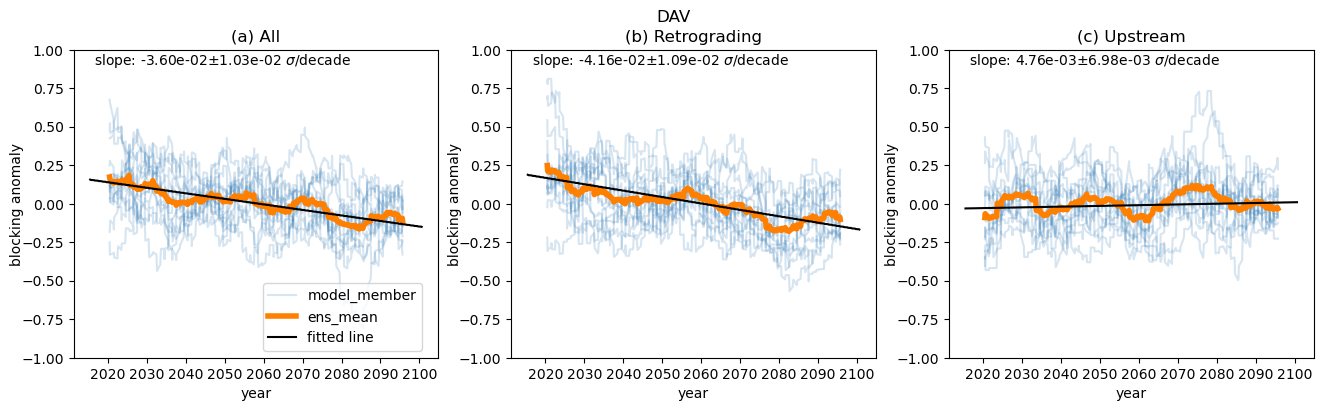

In [12]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
#plt.suptitle('Monthly summer blocking frequency (JJA) given as fraction of blocked days')
colors = ['#377eb8', '#ff7f00', 'black']

plt.suptitle('DAV')

axes[0].set_title('(a) All')
for i,element in enumerate(DAs_all):
    if i == 0:
        axes[0].plot(element['time'],rollmean(element),colors[0],alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[0].plot(average_all['time'],rollmean(average_all),colors[1],label='ens_mean',linewidth=4.0)
axes[0].plot(average_all['time'],y_all, colors[2], label='fitted line')
axes[0].text(average_all['time'][3], 0.9, 'slope: ' + f"{slope_all:.2e}" + "±" + f"{slope_stderr_all:.2e}" + " $\sigma$/decade")
axes[0].set_ylabel('blocking anomaly',labelpad=-2)
axes[0].set_xlabel('year')
axes[0].legend(loc='best', bbox_to_anchor=(0.5, 0., 0.5, 0.5))
axes[0].set_ylim(-1,1)

axes[1].set_title('(b) Retrograding')
for element in DAs_retrograding:
    axes[1].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[1].plot(average_retrograding['time'],rollmean(average_retrograding),colors[1],linewidth=4.0)
axes[1].plot(average_retrograding['time'],y_retrograding,colors[2], label='fitted line')
axes[1].text(average_retrograding['time'][3], 0.9, 'slope: ' + f"{slope_retrograding:.2e}" + "±" + f"{slope_stderr_retrograding:.2e}"+ " $\sigma$/decade")
axes[1].set_ylabel('blocking anomaly',labelpad=-2)
axes[1].set_xlabel('year')
axes[1].set_ylim(-1,1)

axes[2].set_title('(c) Upstream')
for element in DAs_upstream:
    axes[2].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[2].plot(average_upstream['time'],rollmean(average_upstream),colors[1],linewidth=4.0)
axes[2].plot(average_upstream['time'],y_upstream,colors[2], label='fitted line')
axes[2].text(average_upstream['time'][3], 0.9, 'slope: ' + f"{slope_upstream:.2e}" + "±" + f"{slope_stderr_upstream:.2e}"+ " $\sigma$/decade")
axes[2].set_ylabel('blocking anomaly',labelpad=-2)
axes[2].set_xlabel('year')
axes[2].set_ylim(-1,1)

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_future_analysis/PLOTS/DAV_frequency_trend_analysis.png',dpi=300)
